In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
EQ='C:\\ex\\data\\22_열처리 copy.csv'
df=pd.read_csv(EQ)

In [10]:
df['timestamp'] = pd.to_datetime(df['timestamp'])

df = df.sort_values(by='timestamp').reset_index(drop=True)

In [ ]:
# 초의 간격을 파악하는 코드 짜기

In [4]:
df['timestamp']

0     2024-03-01 09:00:00
1     2024-03-01 09:00:10
2     2024-03-01 09:00:20
3     2024-03-01 09:00:30
4     2024-03-01 09:00:40
              ...        
183   2024-03-01 09:32:30
184   2024-03-01 09:32:40
185   2024-03-01 09:32:50
186   2024-03-01 09:33:00
187   2024-03-01 09:33:10
Name: timestamp, Length: 188, dtype: datetime64[us]

In [29]:
import pandas as pd

# timestamp를 datetime 형식으로 변환
df['timestamp'] = pd.to_datetime(df['timestamp'])

# 이전 행과의 시간 차이(초) 계산
gap=df['timestamp'].diff().dt.total_seconds()

print(gap)

KeyError: 'timestamp'

In [21]:
df=df.set_index('timestamp')

In [23]:
df['제어출력'].asfreq('10s')

timestamp
2024-03-01 09:00:00    0.426
2024-03-01 09:00:10    0.463
2024-03-01 09:00:20    0.438
2024-03-01 09:00:30    0.445
2024-03-01 09:00:40    0.421
                       ...  
2024-03-01 09:32:30    0.800
2024-03-01 09:32:40    0.800
2024-03-01 09:32:50    0.800
2024-03-01 09:33:00    0.800
2024-03-01 09:33:10    0.800
Freq: 10s, Name: 제어출력, Length: 200, dtype: float64

In [24]:
norm=df['제어출력'].asfreq('10s')

In [25]:
df.isna().sum()

설비       0
제어출력     0
소입로온도    0
dtype: int64

In [30]:
gaps.norm.value_counts().sort_values()

NameError: name 'gaps' is not defined

In [31]:
path='C:\\ex\\data\\22_열처리 copy 2.csv'
df=pd.read_csv(path)

In [32]:
# timestamp를 datetime 형식으로 변환
df['timestamp'] = pd.to_datetime(df['timestamp'])

# 이전 행과의 시간 차이(초) 계산
gap=df['timestamp'].diff().dt.total_seconds()

print(gap)

0       NaN
1      10.0
2      10.0
3      10.0
4      10.0
       ... 
183    10.0
184    10.0
185    10.0
186    10.0
187    10.0
Name: timestamp, Length: 188, dtype: float64


In [ ]:
path='C:\\ex\\data\\22_열처리 copy 2.csv'
df=pd.read_csv(path)

df['timestamp'] = pd.to_datetime(
    df['timestamp'],
    format='%Y-%m-%d %H:%M:%S',
    errors='coerce'  # 결측치나 오류가 있다면 삭제 함
    )

df = df.set_index('timestamp').sort_index()

df.index.diff().value_counts()

gaps = df.index.to_series().diff().dt.total_seconds()

norm = df[['제어출력']].asfreq('10s')

gaps_norm = norm.index.to_series().diff().dt.total_seconds()

gaps_norm.value_counts().sort_index()

timestamp
10.0    199
Name: count, dtype: int64

In [42]:
path='C:\\ex\\data\\22_열처리 copy 2.csv'
df=pd.read_csv(path)

df['timestamp']=pd.to_datetime(df['timestamp'])
df=df.set_index('timestamp').sort_index()

norm0=df[['제어출력']].asfreq('10s')

print('asfreq 10s 행:', len(norm0), '빈 칸:', int(norm0['제어출력'].isna().sum()))

print('resample 10s 빈 칸:', int(df[['제어출력']].resample('10s').mean()['제어출력'].isna().sum()))

asfreq 10s 행: 200 빈 칸: 22
resample 10s 빈 칸: 16


In [ ]:
# 22_01. 실습 1

In [45]:
df = pd.read_csv(path)
df['timestamp'] = pd.to_datetime(df['timestamp'])

# 시각 열을 시간 인덱스로 올리고 정렬
df = df.set_index('timestamp').sort_index()

# 두 센서(제어출력, 소입로온도)를 1분 단위 평균으로 묶기
a_min = df[['제어출력', '소입로온도']].resample('1min').mean()

# 1분 칸 중 빈 칸이 있는지 확인
print('1분 평균 빈 칸:', int(a_min['제어출력'].isna().sum())) 
print('1분 평균 빈 칸:', int(a_min['소입로온도'].isna().sum())) 

1분 평균 빈 칸: 1
1분 평균 빈 칸: 1


In [50]:
from datetime import datetime, timezone
unix_time=1793756430

In [51]:
timezone.utc

datetime.timezone.utc

In [52]:
datetime.fromtimestamp(unix_time, timezone.utc)

datetime.datetime(2026, 11, 4, 1, 40, 30, tzinfo=datetime.timezone.utc)

In [ ]:
# 22_01. 실습 3

In [ ]:
cols = ['제어출력', '소입로온도']

norm = df[cols].asfreq('10s')
print('총 행:', len(norm))                            # 200
print(norm.isna().sum())                              # 제어출력 22 / 소입로온도 22

filled = df[cols].asfreq('10s', method='ffill')
print('ffill 후:', filled.isna().sum().to_dict()) 

총 행: 200
제어출력     22
소입로온도    22
dtype: int64
ffill 후: {'제어출력': 0, '소입로온도': 0}


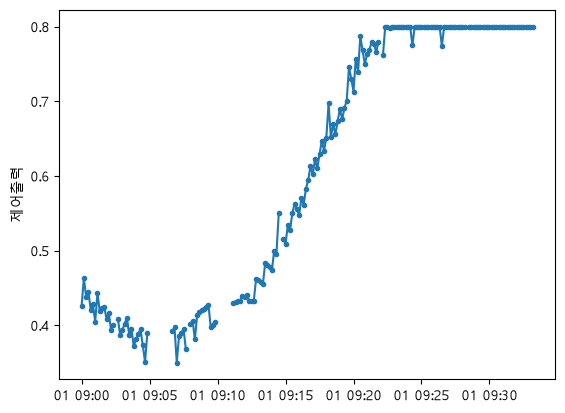

In [60]:
norm = df[["제어출력"]].asfreq("10s")
# 점+ 선으로함께그려야빈구간이보임

plt.rcParams['font.family']='Malgun Gothic'
plt.plot(norm.index, norm["제어출력"], marker=".")
plt.ylabel("제어출력")
plt.show()

In [ ]:
# 22_01. 실습 4

In [ ]:
# 10초 간격으로 x축 정규화 : 두 컬럼만 norm에 할당
norm = df[['제어출력', '소입로온도']].asfreq('10s')

# 각 컬럼의 결측치 개수 및 비율 확인
print('결측 개수:', norm.isna().sum().to_dict())        # 22, 22
print('결측 비율(%):', (norm.isna().mean() * 100).round(1).to_dict())  # 11.0, 11.0

# 빈 시각의 첫 구간을 확인
miss = norm[norm['제어출력'].isna()].index
print('빈 시각 개수:', len(miss), '/ 첫 구간:', miss[0])  # 22 / 09:02:3

결측 개수: {'제어출력': 22, '소입로온도': 22}
결측 비율(%): {'제어출력': 11.0, '소입로온도': 11.0}
빈 시각 개수: 22 / 첫 구간: 2024-03-01 09:02:30


In [ ]:
# 22_01. 실습5

In [61]:
a = df[['제어출력']].asfreq('10s').rename(columns={'제어출력': 'asfreq'})

r = df[['제어출력']].resample('10s').mean().rename(columns={'제어출력': 'resample'})

In [62]:
a

,asfreq
timestamp,
2024-03-01 09:00:00,0.426
2024-03-01 09:00:10,0.463
2024-03-01 09:00:20,0.438
2024-03-01 09:00:30,0.445
2024-03-01 09:00:40,0.421
...,...
2024-03-01 09:32:30,0.800
2024-03-01 09:32:40,0.800
2024-03-01 09:32:50,0.800


In [63]:
r

,resample
timestamp,
2024-03-01 09:00:00,0.426
2024-03-01 09:00:10,0.463
2024-03-01 09:00:20,0.438
2024-03-01 09:00:30,0.445
2024-03-01 09:00:40,0.421
...,...
2024-03-01 09:32:30,0.800
2024-03-01 09:32:40,0.800
2024-03-01 09:32:50,0.800


In [64]:
a.isna().sum()

asfreq    22
dtype: int64

In [65]:
r.isna().sum()

resample    16
dtype: int64

In [66]:
a_min = df[['제어출력']].asfreq('1min').rename(columns={'제어출력': 'asfreq'})

r_min= df[['제어출력']].resample('1min').mean().rename(columns={'제어출력': 'resample'})

In [69]:
a_min.isna().sum()

asfreq    5
dtype: int64

In [70]:
r_min.isna().sum()

resample    1
dtype: int64

In [ ]:
# 22_01. 실습6

In [71]:
norm_10s=df[['제어출력','소입로온도']].asfreq('10s')

print(f'측정 기간 : {norm_10s.index.min()} ~ {norm_10s.index.max()}')

측정 기간 : 2024-03-01 09:00:00 ~ 2024-03-01 09:33:10


In [72]:
norm_10s.isna().sum()

제어출력     22
소입로온도    22
dtype: int64

In [ ]:
print('결측 비율(%):', (norm_10s.isna().mean() * 100).round(1).to_dict())

결측 비율(%): {'제어출력': 11.0, '소입로온도': 11.0}


In [77]:
import numpy as np

In [78]:
s = pd.Series([10.0, np.nan, 40.0], index=pd.to_datetime(
    ['2024-03-01 09:00:00', '2024-03-01 09:00:10', '2024-03-01 09:01:00']))

In [79]:
s

2024-03-01 09:00:00    10.0
2024-03-01 09:00:10     NaN
2024-03-01 09:01:00    40.0
dtype: float64

In [81]:
help(s.interpolate)

Help on method interpolate in module pandas.core.generic:

interpolate(
    method: InterpolateOptions = 'linear',
    *,
    axis: Axis = 0,
    limit: int | None = None,
    inplace: bool = False,
    limit_direction: Literal['forward', 'backward', 'both'] | None = None,
    limit_area: Literal['inside', 'outside'] | None = None,
    **kwargs
) -> Self method of pandas.Series instance
    Fill NaN values using an interpolation method.

    Please note that only ``method='linear'`` is supported for
    DataFrame/Series with a MultiIndex.

    Parameters
    ----------
    method : str, default 'linear'
        Interpolation technique to use. One of:

        * 'linear': Ignore the index and treat the values as equally
          spaced. This is the only method supported on MultiIndexes.
        * 'time': Works on daily and higher resolution data to interpolate
          given length of interval. This interpolates values based on
          time interval between observations.
        * '

In [ ]:
# 결측치 선형 보간
s.interpolate(method='linear')

2024-03-01 09:00:00    10.0
2024-03-01 09:00:10    25.0
2024-03-01 09:01:00    40.0
dtype: float64

In [83]:
s.interpolate(method='time')

2024-03-01 09:00:00    10.0
2024-03-01 09:00:10    15.0
2024-03-01 09:01:00    40.0
dtype: float64

In [ ]:
# 22_02. 실습 1

In [ ]:
import pandas as pd
Path='C:\\ex\\data\\22_열처리 copy 3.csv'
df=pd.read_csv(Path)

df['timestamp']=pd.to_datetime(df['timestamp'])

df=df.set_index('timestamp').sort_index()

norm=df[['제어출력','소입로온도']].asfreq('10s')

print('ffill:', int(norm['제어출력'].ffill().isna().sum()))
print('bfill:', int(norm['제어출력'].bfill().isna().sum()))
print('ffill+bfill:', int(norm['제어출력'].ffill().bfill().isna().sum())) 

In [ ]:
# 22_02. 실습 2

In [84]:
import numpy as np

s = pd.Series([10.0, np.nan, 40.0], index=pd.to_datetime(
    ['2024-03-01 09:00:00', '2024-03-01 09:00:10', '2024-03-01 09:01:00']))

print('선형:', s.interpolate(method='linear').iloc[1],
      '시간:', s.interpolate(method='time').iloc[1])     

lin = norm['제어출력'].interpolate()
tim = norm['제어출력'].interpolate(method='time')

print('다른 칸 수:', int((lin != tim).sum()))  

선형: 25.0 시간: 15.0
다른 칸 수: 0


In [ ]:
isna = norm['제어출력'].isna()
groups = (isna != isna.shift()).cumsum()
runs = isna.groupby(groups).sum()

print('연속 결측:', sorted(runs[runs > 0].tolist(), reverse=True)) 

print('제한 없음:', int(norm['제어출력'].interpolate().isna().sum()))  

print('두 칸 제한:', int(norm['제어출력'].interpolate(limit=2).isna().sum()))

연속 결측: [10, 7, 1, 1, 1, 1, 1]
제한 없음: 0
두 칸 제한: 13


In [ ]:
# 22_02. 실습 4

복원 전: {'제어출력': 22, '소입로온도': 22}
복원 후: {'제어출력': 0, '소입로온도': 0}


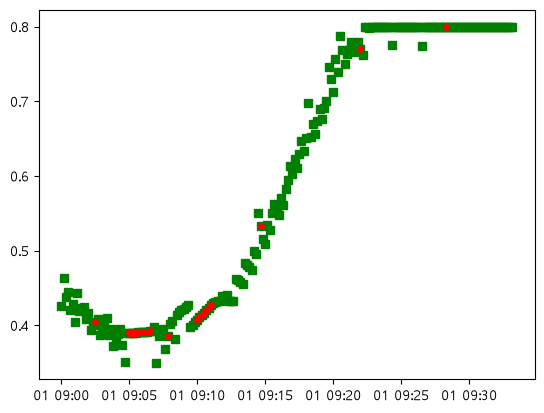

In [95]:

# 두 센서의 복원전 결측 개수 확인
norm=df[['제어출력','소입로온도']].asfreq('10s')
print('복원 전:', norm.isna().sum().to_dict())

# 시간 보간으로 두 센서를 함께 복원
restored=norm.interpolate(method='time')
print('복원 후:', restored.isna().sum().to_dict())

# 채운 자리를 표시한 전후 그래프로 비교

was_na=norm['제어출력'].isna()
import matplotlib.pyplot as plt
plt.plot(restored.index, restored['제어출력'], 'gs')
plt.plot(restored.index[was_na], restored['제어출력'][was_na], 'ro', 
markersize=4)
plt.show()